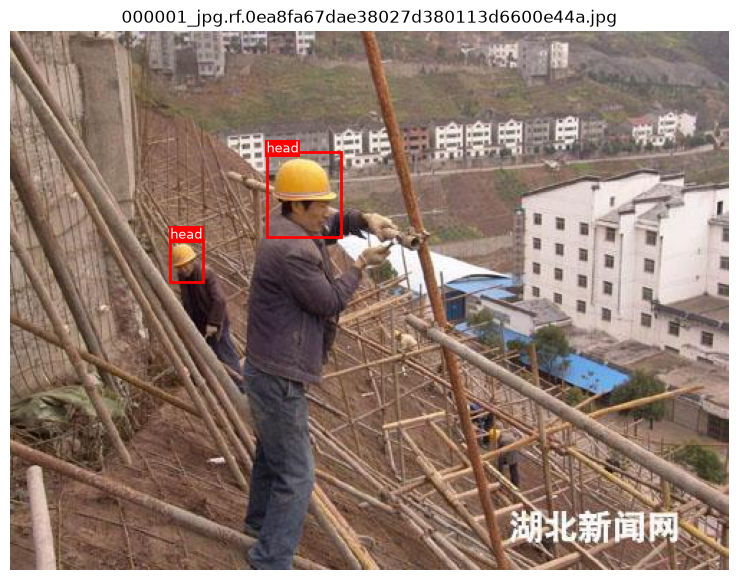

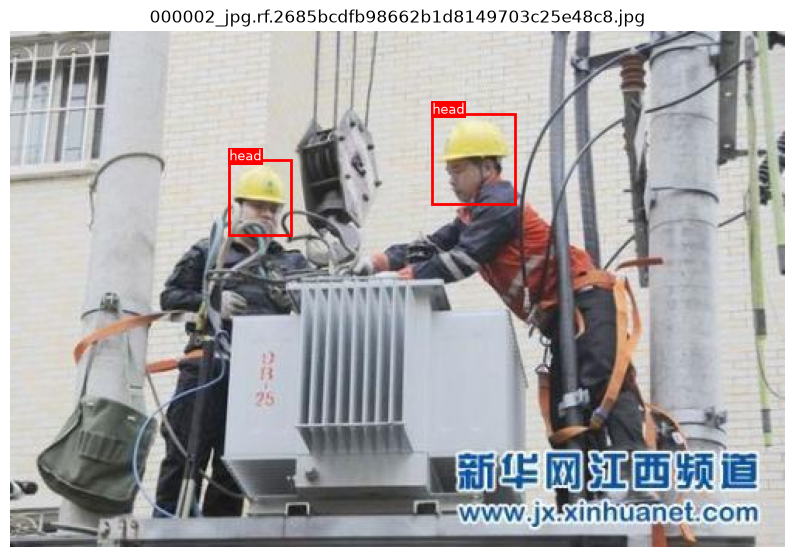

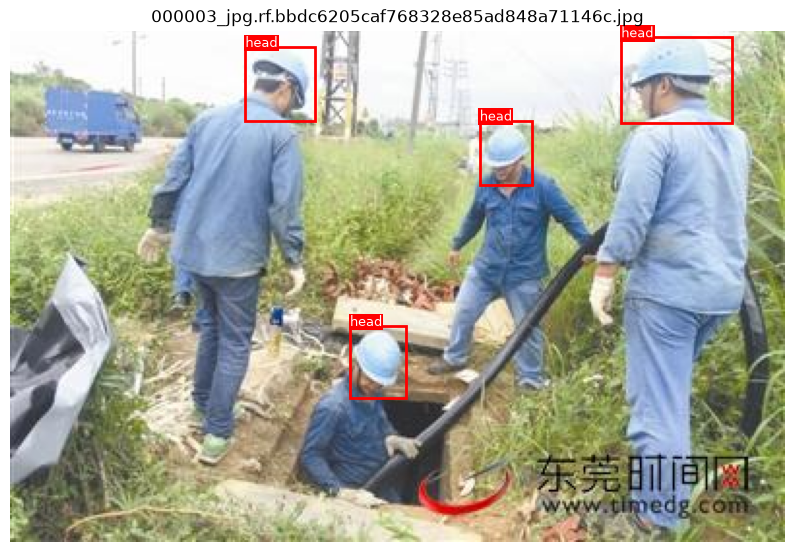

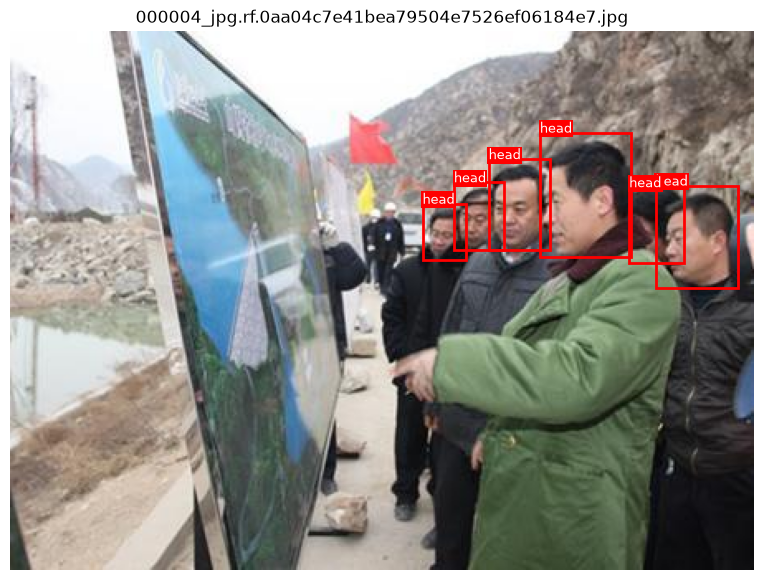

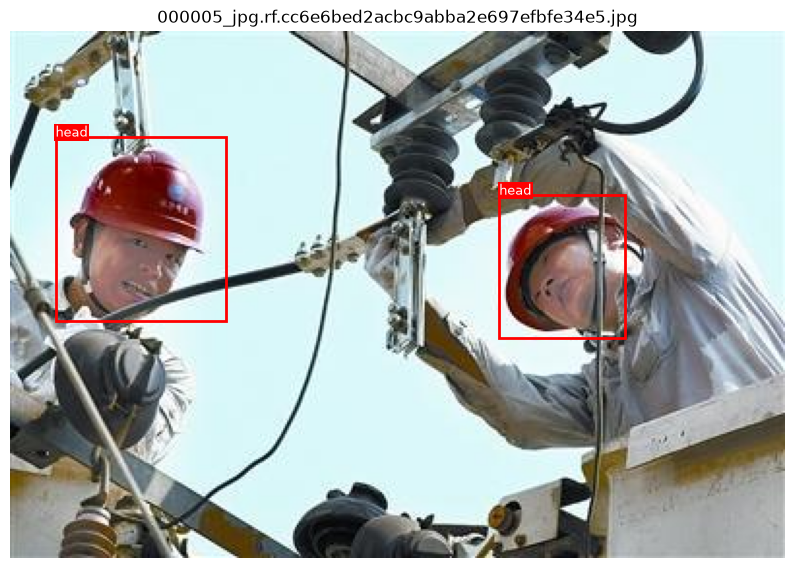

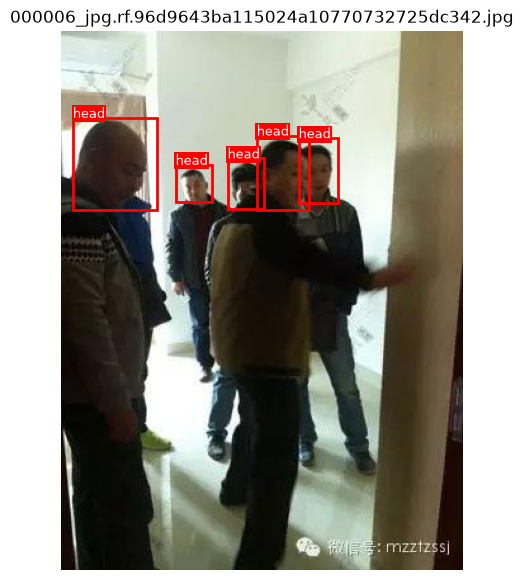

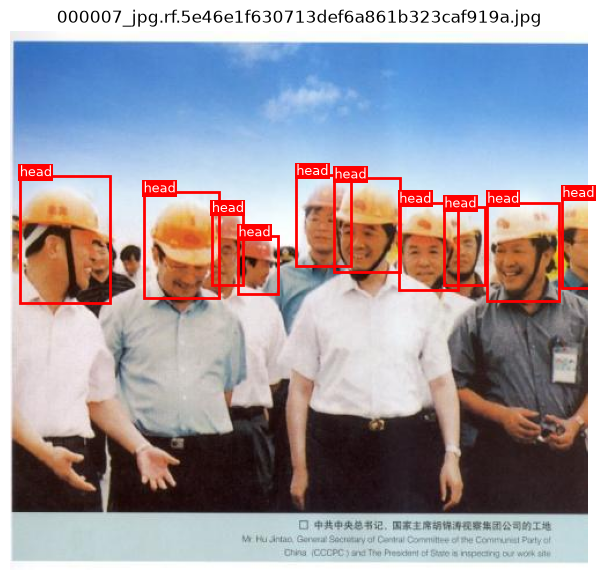

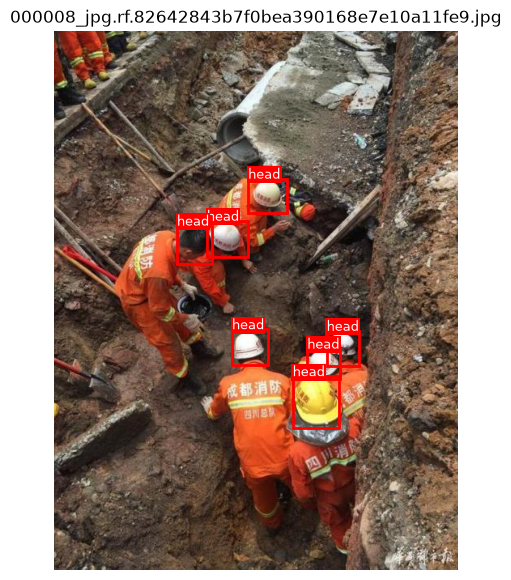

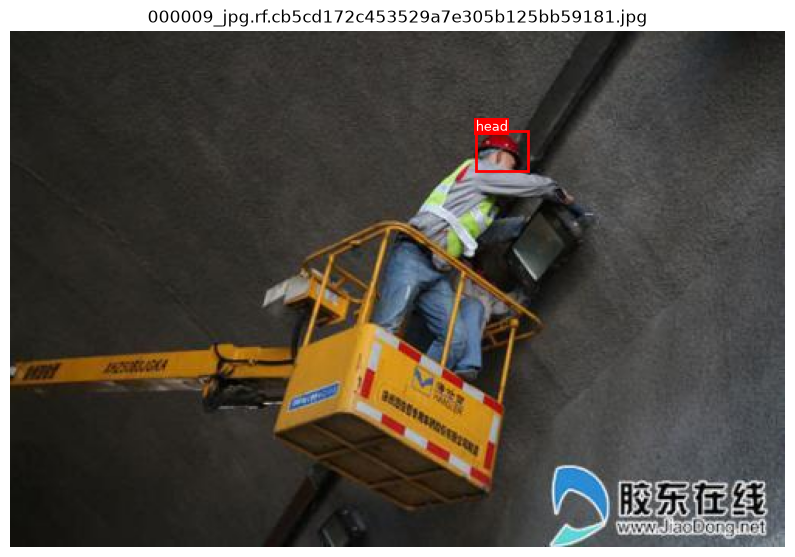

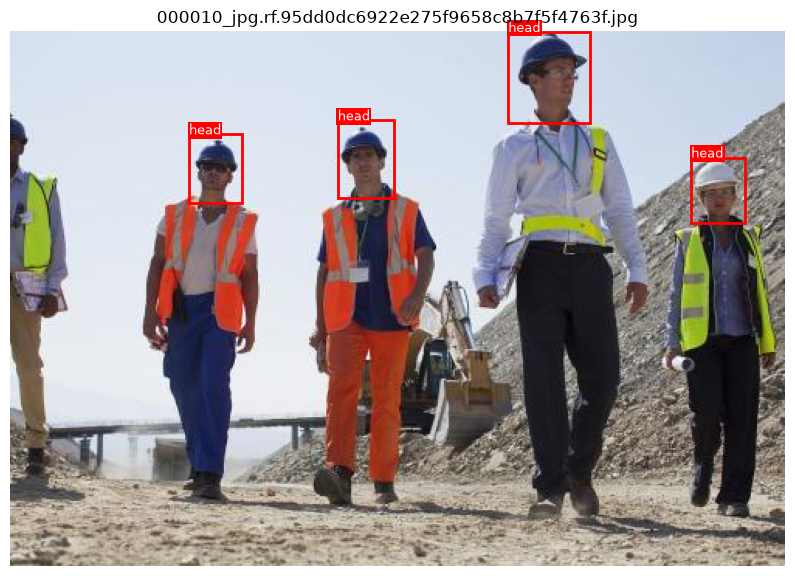

In [1]:
from collections import defaultdict
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# COCO files contain a list of images and a separate list of annotations.
data_dir = Path('/home/dev-tom/projects/my-projects/ISMS/data/yolox_hard_hat')


def preview_images(split='train', num_images=5):
    split_dirs = {'train': 'train2017', 'valid': 'val2017', 'test': 'test2017'}
    if split not in split_dirs:
        raise ValueError(f'Unknown split: {split}. Choose train, valid or test.')
    if num_images < 0:
        raise ValueError('num_images must be non-negative')

    annotation_path = data_dir / 'annotations' / f'{split}.json'
    with annotation_path.open(encoding='utf-8') as file:
        coco = json.load(file)

    annotations_by_image = defaultdict(list)
    for annotation in coco['annotations']:
        annotations_by_image[annotation['image_id']].append(annotation)
    categories = {category['id']: category['name'] for category in coco['categories']}

    images = sorted(coco['images'], key=lambda image: image['file_name'])
    for image_info in images[:num_images]:
        image_path = data_dir / split_dirs[split] / image_info['file_name']
        image = plt.imread(image_path)
        fig, ax = plt.subplots(figsize=(10, 7))
        ax.imshow(image)
        for annotation in annotations_by_image[image_info['id']]:
            x, y, width, height = annotation['bbox']
            ax.add_patch(Rectangle((x, y), width, height, fill=False,
                                   edgecolor='red', linewidth=2))
            label = categories.get(annotation['category_id'], str(annotation['category_id']))
            ax.text(x, y, label, color='white', fontsize=9,
                    bbox={'facecolor': 'red', 'edgecolor': 'none', 'pad': 1})
        ax.set_title(image_info['file_name'])
        ax.axis('off')
        plt.show()


preview_images('train', num_images=10)
